# 04 - Building a Neural Network from Scratch (NumPy only)
**Pipeline:** data -> forward propagation -> loss -> backpropagation -> weight update (SGD / Adam) -> evaluation -> save model.
The reusable class lives in `../src/nn_from_scratch.py`; the key parts are re-explained below.

In [1]:
import sys; sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from nn_from_scratch import NeuralNetwork, SGD, Adam, bce
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 1. Dataset A - Moons (non-linear, 2-D, good for visualizing)

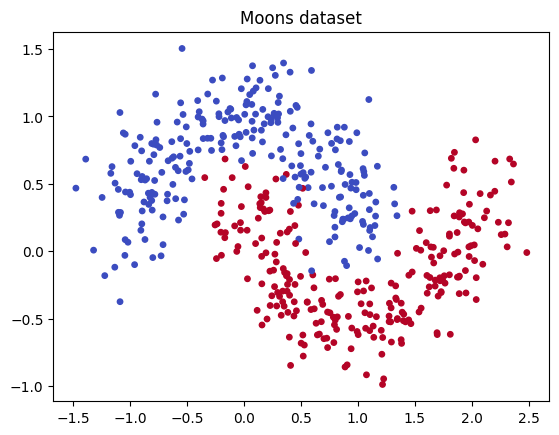

In [2]:
moons = pd.read_csv('../data/moons.csv')
X = moons[['x1','x2']].values; y = moons['label'].values
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
plt.scatter(X[:,0], X[:,1], c=y, cmap='coolwarm', s=15); plt.title('Moons dataset'); plt.show()

## 2. Network design
`[2, 8, 8, 1]` = 2 inputs -> 8 ReLU -> 8 ReLU -> 1 sigmoid output.
- **Forward:** $A^{[l]} = f(A^{[l-1]}W^{[l]} + b^{[l]})$
- **Loss:** binary cross-entropy
- **Backward:** $dZ^{[L]} = \hat y - y$, then $dW^{[l]} = A^{[l-1]T}dZ^{[l]}/m$, $dZ^{[l-1]} = (dZ^{[l]}W^{[l]T}) \odot f'(A^{[l-1]})$
- **Update:** optimizer step on every W and b
- **Init:** He initialization for ReLU

In [3]:
net = NeuralNetwork([2, 8, 8, 1], hidden_act='relu', seed=0)
for k, v in net.params.items(): print(k, v.shape)

W1 (2, 8)
b1 (1, 8)
W2 (8, 8)
b2 (1, 8)
W3 (8, 1)
b3 (1, 1)


## 3. Gradient check (proves backprop is correct)

In [4]:
net_gc = NeuralNetwork([2, 4, 1], hidden_act='tanh', seed=1)
xb, yb = Xtr[:20], ytr[:20]
net_gc.forward(xb); g = net_gc.backward(yb)
eps = 1e-5; max_diff = 0
for key in ['W1', 'W2', 'b1']:
    p = net_gc.params[key]
    for idx in np.ndindex(p.shape):
        old = p[idx]
        p[idx] = old+eps; lp = bce(yb.reshape(-1,1), net_gc.forward(xb))
        p[idx] = old-eps; lm = bce(yb.reshape(-1,1), net_gc.forward(xb))
        p[idx] = old
        max_diff = max(max_diff, abs(g[key][idx] - (lp-lm)/(2*eps)))
print('Max |analytic - numerical| gradient difference:', max_diff)

Max |analytic - numerical| gradient difference: 6.4311885894854925e-12


## 4. Train with SGD vs Adam

epoch  100  loss 0.0749
epoch  200  loss 0.0468


epoch  300  loss 0.0428


epoch  400  loss 0.0363
epoch  500  loss 0.0348
---


epoch  100  loss 0.0304
epoch  200  loss 0.0268


epoch  300  loss 0.0242
epoch  400  loss 0.0222


epoch  500  loss 0.0201


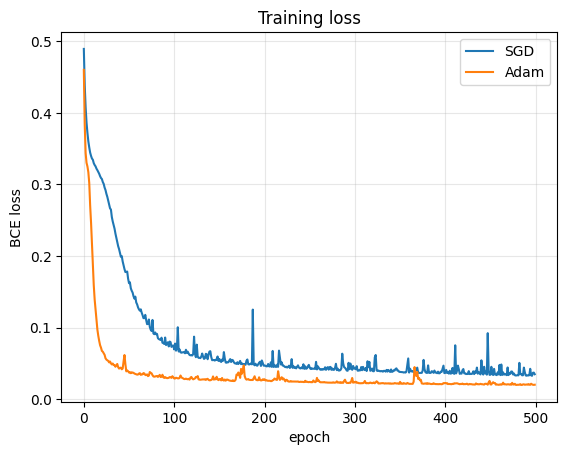

SGD  test acc: 0.97
Adam test acc: 0.97


In [5]:
net_sgd  = NeuralNetwork([2,8,8,1], 'relu', seed=0)
net_adam = NeuralNetwork([2,8,8,1], 'relu', seed=0)
h_sgd  = net_sgd.fit(Xtr, ytr, SGD(lr=0.1),     epochs=500, batch_size=32, verbose=100)
print('---')
h_adam = net_adam.fit(Xtr, ytr, Adam(lr=0.01), epochs=500, batch_size=32, verbose=100)

plt.plot(h_sgd, label='SGD'); plt.plot(h_adam, label='Adam')
plt.xlabel('epoch'); plt.ylabel('BCE loss'); plt.legend(); plt.grid(alpha=.3); plt.title('Training loss'); plt.show()
print('SGD  test acc:', accuracy_score(yte, net_sgd.predict(Xte)))
print('Adam test acc:', accuracy_score(yte, net_adam.predict(Xte)))

## 5. Decision boundary

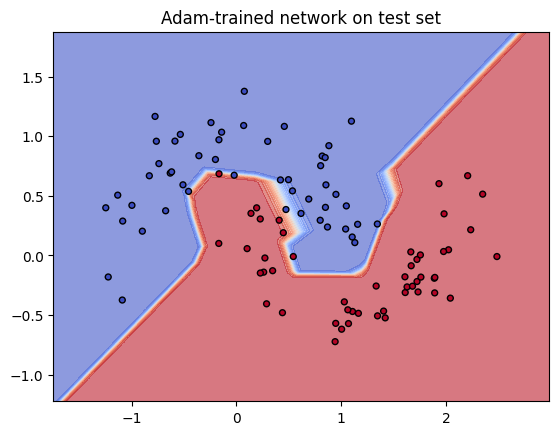

In [6]:
def plot_boundary(net, X, y, title):
    xx, yy = np.meshgrid(np.linspace(X[:,0].min()-.5, X[:,0].max()+.5, 300),
                         np.linspace(X[:,1].min()-.5, X[:,1].max()+.5, 300))
    Z = net.predict_proba(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.contourf(xx, yy, Z, levels=20, cmap='coolwarm', alpha=.6)
    plt.scatter(X[:,0], X[:,1], c=y, cmap='coolwarm', edgecolors='k', s=18); plt.title(title); plt.show()
plot_boundary(net_adam, Xte, yte, 'Adam-trained network on test set')

## 6. Real dataset B - Breast cancer (30 features)
Standardize features (fit scaler on **train only**), then train the same network.

In [7]:
bc = pd.read_csv('../data/breast_cancer.csv')
Xb, yb = bc.drop(columns='target').values, bc['target'].values
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, random_state=42, stratify=yb)
scaler = StandardScaler().fit(Xb_tr)
Xb_tr_s, Xb_te_s = scaler.transform(Xb_tr), scaler.transform(Xb_te)

bc_net = NeuralNetwork([30, 16, 8, 1], 'relu', seed=0)
hist = bc_net.fit(Xb_tr_s, yb_tr, Adam(lr=0.005), epochs=200, batch_size=32, verbose=50)
pred = bc_net.predict(Xb_te_s)
print('\nTest accuracy:', accuracy_score(yb_te, pred))
print(confusion_matrix(yb_te, pred))
print(classification_report(yb_te, pred, target_names=['malignant','benign']))

epoch   50  loss 0.0045
epoch  100  loss 0.0021


epoch  150  loss 0.0017
epoch  200  loss 0.0029

Test accuracy: 0.956140350877193
[[41  1]
 [ 4 68]]
              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



## 7. Compare with scikit-learn (sanity check)

In [8]:
from sklearn.neural_network import MLPClassifier
sk = MLPClassifier((16,8), max_iter=500, random_state=0).fit(Xb_tr_s, yb_tr)
print('sklearn MLP accuracy :', accuracy_score(yb_te, sk.predict(Xb_te_s)))
print('From-scratch accuracy:', accuracy_score(yb_te, pred))

sklearn MLP accuracy : 0.9649122807017544
From-scratch accuracy: 0.956140350877193


## 8. Save the trained model (links back to notebook 01)

In [9]:
joblib.dump({'network': bc_net, 'scaler': scaler}, '../models/scratch_nn_breast_cancer.joblib')
bundle = joblib.load('../models/scratch_nn_breast_cancer.joblib')
re_pred = bundle['network'].predict(bundle['scaler'].transform(Xb_te))
print('Reloaded model gives identical predictions:', np.array_equal(re_pred, pred))

Reloaded model gives identical predictions: True


## 9. Experiments / practice tasks
1. Change hidden activation to `tanh` and `sigmoid`; compare convergence.
2. Try architectures `[30,64,1]`, `[30,16,16,16,1]` - watch for overfitting (add a validation split).
3. Add L2 regularization to `backward()`.
4. Extend the class to softmax output and test on the Iris dataset.

## Conclusion
You implemented forward propagation, BCE loss, backpropagation (verified by gradient check), SGD and Adam, trained on two datasets, matched scikit-learn, and serialized the model.